# Trazabilidad de la arquitectura EDA

Se realizó un análisis con los registros de una ejecución completa de la canción para responder tres preguntas:
1. ¿Se puede seguir el flujo de la experiencia desde la solicitud hasta el cierre?
2. ¿Se puede identificar quién produjo y quién consumió los eventos?
3. ¿La coordinación de escenas y beats usó la referencia musical prevista?

El registro de la consola de Unity aportó los datos que permitieron reconstruir comunicaciones concretas y distinguirlas de operaciones como cargar, preparar o descargar escenas. 

## 1. Objetivo y selección de la ejecución

El recorrido EDA se lee siguiendo las acciones registradas y sus identificadores. `publish` marca una publicación; `receive`, la entrada de un consumidor; `handler_returned`, el retorno de ese manejador; y `handler_dispatch_returned`, el fin de la distribución. Un `event_id` agrupa las etapas de la misma publicación. `run_id` delimita el intento de experiencia que se quiere estudiar.

El nivel `detailed` permite ver receptores individuales; el modo `flow` resume eventos frecuentes. La configuración inicial permite seleccionar un `run_id`. Si se deja en `None`, el notebook elige la primera ejecución identificada.

In [61]:
from pathlib import Path
import re, json, urllib.parse, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from matplotlib.patches import FancyArrowPatch, Patch
import textwrap
import dataframe_image as dfi 

In [62]:
BASE_DIR = Path('Eventos') if Path('Eventos/PUNKO_CONSOLE_LOG.txt').exists() else Path('.')
LOG_PATH = BASE_DIR / 'PUNKO_CONSOLE_LOG.txt'
OUTPUT_DIR = BASE_DIR / 'resultados_trazabilidad_EDA'
SELECT_RUN_ID = None


## 2. Carga y preparación de los registros

El parser conserva el texto y número de línea originales, reconoce categorías `[PGDIAG]` aunque exista un prefijo, decodifica valores porcentuales y mantiene campos desconocidos. Las trazas de Unity y otros mensajes quedan como evidencia auxiliar; no se cuentan como publicaciones o recepciones.

In [63]:
if not LOG_PATH.exists():
    raise FileNotFoundError(f'No se encontró el log: {LOG_PATH.resolve()}')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
source_name = LOG_PATH.name
raw_lines = LOG_PATH.read_text(encoding='utf-8-sig', errors='replace').splitlines()
marker_re = re.compile(r'\[PGDIAG\]\[([^\]]+)\]')
pair_re = re.compile(r'(?<!\S)([^\s=]+)=([^\s]*)')
records, parse_issues, complements = [], [], []

for line_no, line in enumerate(raw_lines, 1):
    marker = marker_re.search(line)
    if not marker:
        kind = 'traza_llamada' if re.match(r'^(UnityEngine\.|[A-Za-z_$][\w.$<>/`:+-]*:)', line.strip()) else 'mensaje_no_estructurado'
        complements.append({'file': source_name, 'line_no': line_no, 'kind': kind, 'raw_text': line})
        continue
    category = marker.group(1)
    payload = line[marker.end():].strip()
    pairs = list(pair_re.finditer(payload))
    fields = {}
    for m in pairs:
        key, value = m.group(1), m.group(2)
        fields[key] = urllib.parse.unquote(value)
    residue = pair_re.sub('', payload).strip()
    issue = None
    if not category: issue = 'categoría vacía'
    elif not pairs: issue = 'marcador estructurado sin campos clave=valor'
    elif residue: issue = f'texto no interpretado antes/después de campos: {residue[:160]}'
    row = {'file': source_name, 'line_no': line_no, 'category': category, 'raw_text': line,
           'parse_issue': issue, 'unparsed_residue': residue, **fields}
    records.append(row)
    if issue: parse_issues.append(row)

df = pd.DataFrame(records)
complement_df = pd.DataFrame(complements, columns=['file','line_no','kind','raw_text'])
issues_df = pd.DataFrame(parse_issues)

# Solo campos conocidos con magnitud numérica se convierten a tipos anulables.
# IDs (run_id, event_id, operation_id, instance_id, channel_id) permanecen textuales.
numeric_fields = {'record_seq':'Int64','mono_s':'Float64','segment_index':'Int64',
 'musical_time_s':'Float64','music_time_s':'Float64','timing_error_s':'Float64',
 'duration_s':'Float64','actual_duration_s':'Float64','start_time_s':'Float64','end_time_s':'Float64',
 'requested_time_s':'Float64','scheduled_time_s':'Float64','observed_time_s':'Float64',
 'publication_delay_s':'Float64','arrival_song_time':'Float64','lead_time_s':'Float64','reveal_time_s':'Float64',
 'preload_lead_s':'Float64','transition_lead_s':'Float64','transition_reveal_s':'Float64','max_beat_lateness_s':'Float64',
 'preload_lead_seconds':'Float64','fade_duration_s':'Float64','estimated_bpm':'Float64','success_rate':'Float64',
 'intensity':'Float64','minimum_intensity':'Float64','recent_intensity':'Float64','score_delta':'Float64',
 'beat_index':'Int64','receiver_count':'Int64','total':'Int64','emitted_count':'Int64','requested_count':'Int64',
 'arrival_index':'Int64','throw_count':'Int64','runtime_count':'Int64',
 'preloader_count':'Int64','loaded_scene_count':'Int64','start_index':'Int64','beat_count':'Int64','amount':'Int64',
 'beats_per_spawn':'Int64','active_limit':'Int64','final_score':'Int64','high_score':'Int64'}

conversion_issues=[]
for col, dtype in numeric_fields.items():
    if col not in df: continue
    before = df[col].copy()
    parsed = pd.to_numeric(before.replace({'none':pd.NA,'pending':pd.NA,'unavailable':pd.NA,'' : pd.NA}), errors='coerce')
    bad = before.notna() & ~before.astype(str).str.lower().isin(['none','pending','unavailable','']) & parsed.isna()
    for idx in df.index[bad]:
        conversion_issues.append({'file':source_name,'line_no':int(df.loc[idx,'line_no']),'field':col,'value':before.loc[idx],'problem':'valor no convertible'})
    df[col] = parsed.astype(dtype)
conversion_issues_df = pd.DataFrame(conversion_issues, columns=['file','line_no','field','value','problem'])
boolean_fields=['externally_controlled','prepared','stopping','preload_before_playback',
 'release_unused_assets','hold_last_scene_until_song_ends','full','intense','is_prepared','is_playing',
 'ending','completion_sent','ending_cancelled','upload_finished','is_new_high_score','new_high_score',
 'cancelled','credits_in_progress','main_menu_loaded','left_launched','right_launched']

boolean_issues=[]
for col in boolean_fields:
    if col not in df: continue
    before=df[col].copy(); normalized=before.astype('string').str.lower()
    mapped=normalized.map({'true':True,'false':False})
    bad=before.notna() & ~normalized.isin(['true','false','none','pending','unavailable',''])
    for idx in df.index[bad]:
        boolean_issues.append({'file':source_name,'line_no':int(df.loc[idx,'line_no']),'field':col,'value':before.loc[idx],'problem':'valor no convertible a booleano'})
    df[col]=mapped.astype('boolean')
if boolean_issues:
    conversion_issues_df=pd.concat([conversion_issues_df,pd.DataFrame(boolean_issues)],ignore_index=True)

special_tokens = pd.DataFrame([{'field':c,'value':v,'count':int(n)} for c in df.columns
  if c not in numeric_fields for v,n in df[c].dropna().astype(str).value_counts().items()
  if v.lower() in {'none','pending','unavailable'}], columns=['field','value','count'])


In [64]:
def valid_token(value):
    return pd.notna(value) and str(value).strip().lower() not in {'none','pending','unavailable',''}
def clean_scene(value):
    if not valid_token(value): return pd.NA
    text=str(value)
    return text[5:] if text.startswith('name=') else text

df['capture_id']='capture-001' 
if 'run_id' not in df: df['run_id']=pd.NA

df['run_key']=df['run_id'].where(df['run_id'].map(valid_token),pd.NA).astype('string')
headers=df[df.category.eq('HEADER')].copy()
run_ids=sorted(df.loc[df.run_key.notna(),'run_key'].astype(str).unique())

if SELECT_RUN_ID is None: SELECTED_RUN_ID=run_ids[0] if run_ids else None
else:
    SELECTED_RUN_ID=str(SELECT_RUN_ID)
    if SELECTED_RUN_ID not in run_ids:
        warnings.warn(f'No se encontro SELECT_RUN_ID={SELECTED_RUN_ID!r}; se usara la primera ejecucion disponible.')
        SELECTED_RUN_ID=run_ids[0] if run_ids else None
run_df=df[df.run_key.eq(SELECTED_RUN_ID)].copy() if SELECTED_RUN_ID else df.copy()

run_markers=run_df[run_df.category.eq('RUN')]
starts=run_markers[run_markers.action.eq('started')]; ends=run_markers[run_markers.action.eq('ended')]
run_start_mono=float(starts.mono_s.iloc[0]) if len(starts) else float(run_df.mono_s.min())
run_end_mono=float(ends.mono_s.iloc[-1]) if len(ends) else float(run_df.mono_s.max())
run_duration_s=run_end_mono-run_start_mono
prior=headers[headers.line_no.le(run_df.line_no.min())] if len(run_df) else headers
header=prior.iloc[-1] if len(prior) else (headers.iloc[0] if len(headers) else pd.Series(dtype='object'))
experience=run_df.experience.dropna().iloc[0] if 'experience' in run_df and run_df.experience.notna().any() else header.get('experience')
mode_value=run_df['mode'].dropna().iloc[0] if 'mode' in run_df and run_df['mode'].notna().any() else header.get('mode')
platform=header.get('platform'); log_level=header.get('log_level')

summary=pd.DataFrame([
 {'Indicador':'Lineas originales','Resultado':f'{len(raw_lines):,}'},
 {'Indicador':'Registros PGDIAG','Resultado':f'{len(df):,}'},
 {'Indicador':'Ejecuciones identificadas','Resultado':str(len(run_ids))},
 {'Indicador':'Ejecucion analizada','Resultado':str(SELECTED_RUN_ID or 'No identificada')},
 {'Indicador':'Plataforma','Resultado':str(platform)},
 {'Indicador':'Experiencia / modalidad','Resultado':f'{experience} / {mode_value}'},
 {'Indicador':'Nivel de diagnostico','Resultado':str(log_level)}])
 
display(summary)

display(Markdown(f"Las lineas de consola y trazas se conservaron como evidencia auxiliar ({len(complement_df):,}); el analisis principal utiliza PGDIAG. Duracion observada entre marcadores de esta ejecucion: **{run_duration_s:.3f} s**."))

,Indicador,Resultado
0,Lineas originales,"102,061"
1,Registros PGDIAG,"9,426"
2,Ejecuciones identificadas,1
3,Ejecucion analizada,c5821b1ffe684c4dbaf68681ecc7f269
4,Plataforma,WindowsEditor
5,Experiencia / modalidad,PUNKO / full
6,Nivel de diagnostico,detailed


Las lineas de consola y trazas se conservaron como evidencia auxiliar (92,635); el analisis principal utiliza PGDIAG. Duracion observada entre marcadores de esta ejecucion: **201.440 s**.

## 3. Pregunta 1: ¿Se puede seguir el flujo de la experiencia desde la solicitud hasta el cierre?

El recorrido esperado combina comunicación por eventos y operaciones de ciclo de vida. Los eventos conectan componentes; las operaciones de carga y preparación describen trabajo realizado entre esas comunicaciones. En modalidad completa, `FullExperienceDirector` consulta el reloj musical y activa segmentos; el cambio de segmento no inicia otra experiencia.

```text
Selección del usuario → ExperienceRequested → carga y preparación
→ AppStateMachine publica ExperienceReady → SequenceDirector solicita PlayableDirector.Play()
→ FullExperienceDirector sigue el reloj musical → ExperienceSceneActivation
→ ExperienceSceneBootstrap activa el contenido → SongFinished → ExperienceCompleted → resultados → menú
```

`ExperienceCore` es una escena de servicios compartidos. `play_request` demuestra que se solicitó la reproducción; el estado observado es una evidencia posterior distinta. Preparar una escena tampoco significa que su gameplay ya esté activo.

In [65]:
coverage_specs=[
 ('Solicitud de experiencia',lambda d:(d.action.eq('experience_request_created')) | (d.event.eq('ExperienceRequested') & d.action.eq('publish'))),
 ('Recepción y validación',lambda d:d.action.isin(['experience_request_received','request_validation'])),
 ('Inicio de carga y preparación',lambda d:d.category.eq('OP') & d.action.isin(['scene_load_additive','full_sequence_prepare','scene_prepare','preloader'])),
 ('Preparación completada',lambda d:d.action.eq('segment_scene_prepared') | (d.action.eq('full_sequence_prepare') & d.phase.eq('finish'))),
 ('ExperienceReady publicado por AppStateMachine',lambda d:d.event.eq('ExperienceReady') & d.action.eq('publish') & d.component.eq('AppStateMachine')),
 ('ExperienceReady recibido por SequenceDirector',lambda d:d.event.eq('ExperienceReady') & d.action.eq('receive') & d.receiver.eq('SequenceDirector')),
 ('Solicitud de reproducción',lambda d:d.action.eq('play_request')),
 ('Estado observado del PlayableDirector',lambda d:d.action.eq('play_state_observed')),
 ('Activación y desactivación de segmentos',lambda d:d.action.isin(['segment_active','segment_deactivation_requested']) | d.event.eq('ExperienceSceneActivation')),
 ('Final de canción',lambda d:(d.event.eq('SongFinished') & d.action.eq('publish')) | d.action.isin(['playback_finished','song_finished_received'])),
 ('Cierre, resultados y retorno al menú',lambda d:d.event.eq('ExperienceCompleted') | d.action.isin(['run_result_published','results_received','transition_to_menu','ended']))]

coverage_rows=[]
for stage,mask_fn in coverage_specs:
    hits=run_df.loc[mask_fn(run_df)]
    status='Verificado en esta captura' if len(hits) else 'Sin evidencia en esta captura'
    if stage=='Recepción y validación' and len(hits) and not {'experience_request_received','request_validation'}.issubset(set(hits.action)): status='Parcialmente observado'
    if stage=='Cierre, resultados y retorno al menú':
        found=[bool(hits.event.eq('ExperienceCompleted').any()),bool(hits.action.eq('results_received').any()),bool(hits.action.eq('transition_to_menu').any())]
        if any(found) and not all(found): status='Parcialmente observado'
        elif not any(found): status='Sin evidencia en esta captura'
    refs='; '.join(f"seq {int(r.record_seq)} / linea {int(r.line_no)}" for _,r in hits.head(3).iterrows())
    if len(hits)>3: refs+=f" (+{len(hits)-3} registros)"
    comps=sorted(set(hits.component.dropna().astype(str)) | set(hits.receiver.dropna().astype(str))) if len(hits) else []
    if len(comps)>6: comps=comps[:6]+[f"y {len(comps)-6} más"]
    coverage_rows.append({'Etapa':stage,'Evidencia observada':'; '.join(hits.action.dropna().astype(str).unique()) if len(hits) else '—','Componentes principales':'; '.join(comps),'Estado':status,'Registros de referencia':refs})

coverage_main=pd.DataFrame(coverage_rows)
display(coverage_main)

verified=int(coverage_main.Estado.eq('Verificado en esta captura').sum()); partial=int(coverage_main.Estado.eq('Parcialmente observado').sum()); no_evidence=int(coverage_main.Estado.eq('Sin evidencia en esta captura').sum())
if verified==len(coverage_main): display(Markdown(f"En esta captura se encontró evidencia para los **{verified} pasos** del recorrido principal, desde la solicitud hasta el retorno al menú."))
else: display(Markdown(f"Cobertura: **{verified} verificados**, **{partial} parciales** y **{no_evidence} sin evidencia**. La ausencia de una línea no demuestra por sí sola que una acción no ocurriera."))

,Etapa,Evidencia observada,Componentes principales,Estado,Registros de referencia
0,Solicitud de experiencia,experience_request_created; publish,ExperienceLaunchButton,Verificado en esta captura,seq 27 / linea 293; seq 33 / linea 351
1,Recepción y validación,experience_request_received; request_validation,AppStateMachine; SceneFlowManager,Verificado en esta captura,seq 35 / linea 371; seq 36 / linea 383; seq 44...
2,Inicio de carga y preparación,scene_load_additive; full_sequence_prepare; sc...,AlexThrowPool; BulletPool; EnemyPool; Experien...,Verificado en esta captura,seq 45 / linea 562; seq 48 / linea 597; seq 53...
3,Preparación completada,segment_scene_prepared; full_sequence_prepare,ExperienceSceneBootstrap; FullExperienceDirector,Verificado en esta captura,seq 97 / linea 919; seq 112 / linea 1039; seq ...
4,ExperienceReady publicado por AppStateMachine,publish,AppStateMachine,Verificado en esta captura,seq 147 / linea 1329
5,ExperienceReady recibido por SequenceDirector,receive,SequenceDirector,Verificado en esta captura,seq 152 / linea 1383
6,Solicitud de reproducción,play_request,SequenceDirector,Verificado en esta captura,seq 154 / linea 1405
7,Estado observado del PlayableDirector,play_state_observed,SequenceDirector,Verificado en esta captura,seq 155 / linea 1417
8,Activación y desactivación de segmentos,publish; receive; handler_returned; handler_di...,ExperienceSceneBootstrap; FullExperienceDirector,Verificado en esta captura,seq 193 / linea 1920; seq 194 / linea 1929; se...
9,Final de canción,playback_finished; publish; song_finished_rece...,SceneFlowManager; SequenceDirector,Verificado en esta captura,seq 9224 / linea 99665; seq 9225 / linea 99670...


En esta captura se encontró evidencia para los **11 pasos** del recorrido principal, desde la solicitud hasta el retorno al menú.

### Línea temporal observada

En esta figura se resumen los hitos seleccionados de la ejecución. Cada punto corresponde a un registro de la etapa indicada en el eje vertical. Su posición horizontal muestra cuántos segundos han transcurrido desde el marcador de inicio de la ejecución. El registro usa una marca de tiempo interna que avanza durante la captura; siendo representado como el tiempo transcurrido.

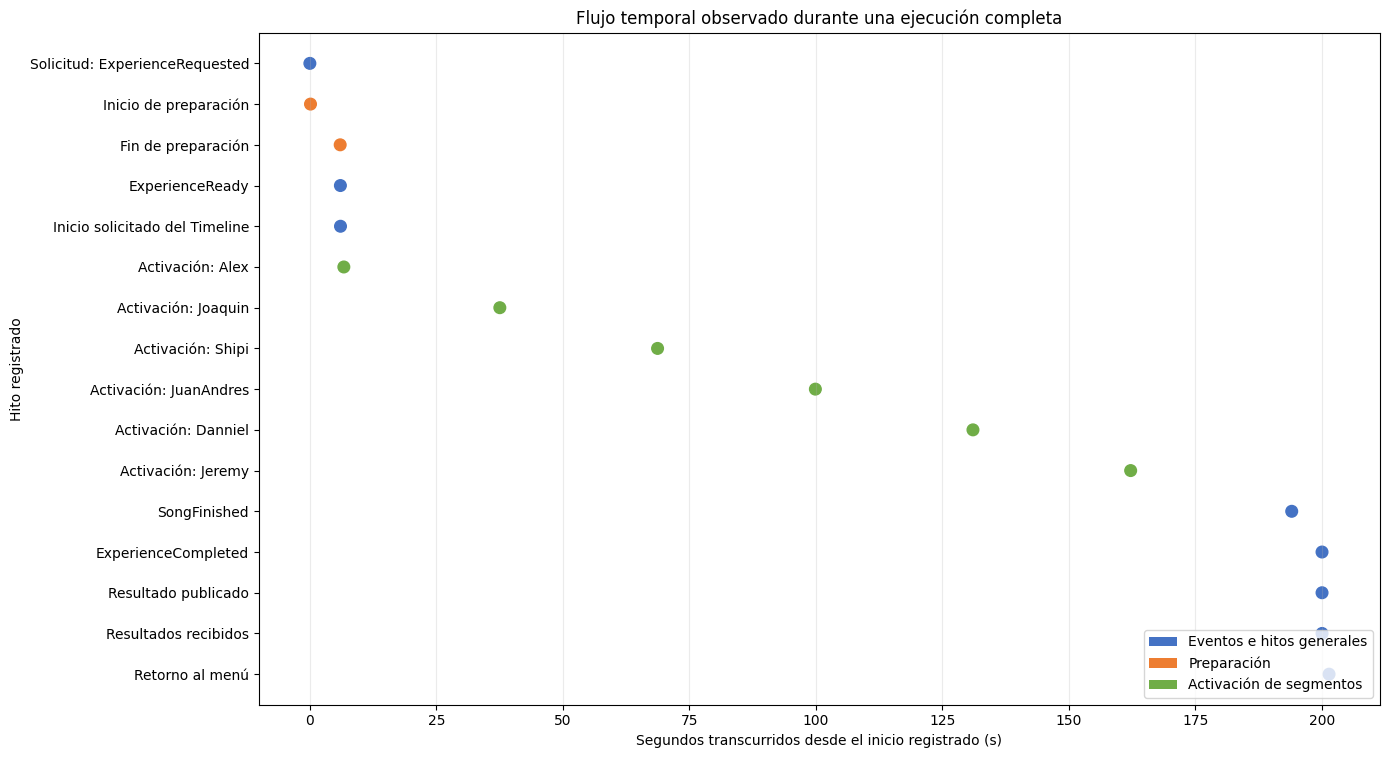

,Etapa,Tiempo desde inicio (s),musical_time_s,record_seq,line_no
0,Solicitud: ExperienceRequested,0.0021,<NA>,33,351
1,Inicio de preparación,0.1293,0.0,83,821
2,Fin de preparación,5.9965,0.0,141,1281
3,ExperienceReady,6.0375,0.0,147,1329
4,Inicio solicitado del Timeline,6.0576,0.0,154,1405
5,Activación: Alex,6.7175,0.017769,217,2276
6,Activación: Joaquin,37.5471,31.160552,3322,38673
7,Activación: Shipi,68.7215,62.342261,4606,52200
8,Activación: JuanAndres,99.9080,93.503056,5797,64302
9,Activación: Danniel,131.0527,124.669642,7180,79648


In [66]:
timeline_rows=[]

def add_timeline(mask,stage,scene=False):
    for _,r in run_df[mask].iterrows():
        name=f"Activación: {clean_scene(r.get('scene'))}" if scene else stage
        timeline_rows.append({'Etapa':name,'Tiempo desde inicio (s)':float(r.mono_s)-run_start_mono,'mono_s':float(r.mono_s),'musical_time_s':r.get('musical_time_s'),'record_seq':r.get('record_seq'),'line_no':int(r.line_no),'component':r.get('component')})

add_timeline(run_df.event.eq('ExperienceRequested') & run_df.action.eq('publish'),'Solicitud: ExperienceRequested')
add_timeline(run_df.category.eq('OP') & run_df.action.eq('full_sequence_prepare') & run_df.phase.eq('start'),'Inicio de preparación')
add_timeline(run_df.category.eq('OP') & run_df.action.eq('full_sequence_prepare') & run_df.phase.eq('finish'),'Fin de preparación')
add_timeline(run_df.event.eq('ExperienceReady') & run_df.action.eq('publish'),'ExperienceReady')
add_timeline(run_df.action.eq('play_request'),'Inicio solicitado del Timeline')
add_timeline(run_df.action.eq('segment_active'),'Activación de segmento',True)
add_timeline(run_df.event.eq('SongFinished') & run_df.action.eq('publish'),'SongFinished')
add_timeline(run_df.event.eq('ExperienceCompleted') & run_df.action.eq('publish'),'ExperienceCompleted')
add_timeline(run_df.action.eq('run_result_published'),'Resultado publicado')
add_timeline(run_df.action.eq('results_received'),'Resultados recibidos')
add_timeline(run_df.category.eq('OP') & run_df.action.eq('transition_to_menu') & run_df.phase.eq('finish'),'Retorno al menú')
timeline_df=pd.DataFrame(timeline_rows).sort_values('Tiempo desde inicio (s)') if timeline_rows else pd.DataFrame()

if len(timeline_df):
    stages=list(dict.fromkeys(timeline_df.Etapa.tolist())); ymap={s:i for i,s in enumerate(stages)}; timeline_df['y']=timeline_df.Etapa.map(ymap)
    colors=['#70AD47' if s.startswith('Activación') else '#ED7D31' if 'preparación' in s.lower() else '#4472C4' for s in timeline_df.Etapa]
    fig,ax=plt.subplots(figsize=(14,max(5,.48*len(stages)))); ax.scatter(timeline_df['Tiempo desde inicio (s)'],timeline_df.y,c=colors,s=70)
    ax.set_yticks(range(len(stages)),stages); ax.invert_yaxis(); ax.set_xlabel('Segundos transcurridos desde el inicio registrado (s)'); ax.set_ylabel('Hito registrado')
    ax.set_title('Flujo temporal observado durante una ejecución completa'); ax.grid(axis='x',alpha=.25)
    
    ax.legend(handles=[Patch(facecolor='#4472C4',label='Eventos e hitos generales'),Patch(facecolor='#ED7D31',label='Preparación'),Patch(facecolor='#70AD47',label='Activación de segmentos')],loc='lower right',frameon=True)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/'flujo_temporal_eda.png',dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
    display(timeline_df[['Etapa','Tiempo desde inicio (s)','musical_time_s','record_seq','line_no']].round(4))
else: 
    display(Markdown('No hay suficientes hitos para construir la línea temporal.'))

Contestando a la primera pregunta, cada punto en la figura marca cuándo se registró el hito de su fila. Los puntos verdes identifican las activaciones individuales de las escenas de los Skeepers. Los naranjas muestran el inicio y fin de la preparación. Los puntos azules muestran la solicitud, el inicio global de la reproducción y los hitos de cierre. Los que aparecen más a la derecha ocurrieron más tarde.


Cada punto en la figura marca cuándo se registró el hito de su fila. Los puntos verdes identifican las activaciones individuales de las escenas de los Skeepers. Los naranjas muestran el inicio y fin de la preparación. Los puntos azules muestran la solicitud, el inicio global de la reproducción y los hitos de cierre. Los que aparecen más a la derecha ocurrieron más tarde.

## 4. Pregunta: 2. ¿Se puede identificar quién produjo y quién consumió los eventos?

La tabla principal resume relaciones observadas, no cada registro individual. Se agrupa por productor, tipo de evento y consumidor. Los `event_id` completos y las referencias de línea se conservan en el anexo y los CSV.

Una publicación puede ser recibida por varios componentes; por eso las recepciones pueden superar a las publicaciones. La correlación requiere `event_id` válido y un contexto compatible de ejecución.

In [67]:
pubs=df[df.action.eq('publish')].copy() if 'action' in df else df.iloc[0:0].copy()
recs=df[df.action.eq('receive')].copy() if 'action' in df else df.iloc[0:0].copy()
subs=df[df.action.astype('string').str.startswith('subscription_',na=False)].copy() if 'action' in df else df.iloc[0:0].copy()

catalog=[]
for ch,g in df[df.channel.notna()].groupby('channel',dropna=False) if 'channel' in df else []:
    p=g[g.action.eq('publish')] if 'action' in g else g.iloc[0:0]
    r=g[g.action.eq('receive')] if 'action' in g else g.iloc[0:0]
    s=g[g.action.astype('string').str.startswith('subscription_',na=False)] if 'action' in g else g.iloc[0:0]
    catalog.append({'channel':ch,'channel_ids':'; '.join(sorted(g.channel_id.dropna().astype(str).unique())) if 'channel_id' in g else '',
      'publisher_components':'; '.join(sorted(p.component.dropna().astype(str).unique())) if 'component' in p else '',
      'receiver_components':'; '.join(sorted(r.receiver.dropna().astype(str).unique())) if 'receiver' in r else '',
      'publisher_instances_scenes':'; '.join(sorted((p.component.fillna('?').astype(str)+'#'+p.instance_id.fillna('?').astype(str)+'@'+p.scene.fillna('?').astype(str)).unique())) if len(p) else '',
      'receiver_instances_scenes':'; '.join(sorted((r.receiver.fillna('?').astype(str)+'#'+r.receiver_instance_id.fillna('?').astype(str)+'@'+r.scene.fillna('?').astype(str)).unique())) if len(r) else '',
      'publications':len(p),'receives':len(r),'subscriptions':len(s)})
event_catalog=pd.DataFrame(catalog)


def compatible(a,b):
    for c in ['capture_id','run_key']:
        av,bv=a.get(c),b.get(c)
        if pd.isna(av) != pd.isna(bv) or (pd.notna(av) and str(av)!=str(bv)): return False
    return not (valid_token(a.get('channel_id')) and valid_token(b.get('channel_id')) and str(a.channel_id)!=str(b.channel_id)) and not (valid_token(a.get('channel')) and valid_token(b.get('channel')) and str(a.channel)!=str(b.channel))
valid_pubs=pubs[pubs.event_id.map(valid_token)] if 'event_id' in pubs else pubs.iloc[0:0]
valid_recs=recs[recs.event_id.map(valid_token)] if 'event_id' in recs else recs.iloc[0:0]
rec_by_event={str(eid):g for eid,g in valid_recs.groupby('event_id',sort=False)}

chain=[]; matched_rec=set(); matched_pub=set()
for pi,p in valid_pubs.iterrows():
    candidates=rec_by_event.get(str(p.event_id),valid_recs.iloc[0:0])
    matches=[(ri,r) for ri,r in candidates.iterrows() if compatible(p,r)]
    if matches:
        matched_pub.add(pi)
        for ri,r in matches:
            matched_rec.add(ri)
            chain.append({'capture_id':p.capture_id,'run_id':p.run_key,'event_id':p.event_id,'channel':p.get('channel'),'channel_id':p.get('channel_id'),
              'publisher':p.get('component'),'publisher_instance':p.get('instance_id'),'publisher_scene':p.get('scene'),
              'receiver':r.get('receiver'),'receiver_instance':r.get('receiver_instance_id'),'receiver_scene':r.get('scene'),
              'publish_seq':p.get('record_seq'),'receive_seq':r.get('record_seq'),'publish_line':p.line_no,'receive_line':r.line_no,
              'publish_mono_s':p.get('mono_s'),'receive_mono_s':r.get('mono_s'),
              'instrumented_delta_ms':(float(r.mono_s)-float(p.mono_s))*1000 if pd.notna(r.get('mono_s')) and pd.notna(p.get('mono_s')) else pd.NA,
              'correlation':'event_id + capture/run + compatible channel'})
unmatched_pubs=pubs.loc[~pubs.index.isin(matched_pub)].copy()
unmatched_recs=recs.loc[~recs.index.isin(matched_rec)].copy()
event_chains=pd.DataFrame(chain)

def norm_id(v): return str(v) if valid_token(v) else ''
event_lookup={}
for _,p in pubs.iterrows(): event_lookup[(norm_id(p.get('run_key')),norm_id(p.get('event_id')),norm_id(p.get('channel_id')))]=p.get('event')

if len(event_chains):
    event_chains['event']=event_chains.apply(lambda r:event_lookup.get((norm_id(r.get('run_id')),norm_id(r.get('event_id')),norm_id(r.get('channel_id'))),pd.NA),axis=1)
else: 
    event_chains['event']=pd.Series(dtype='string')
event_chains_run=event_chains[event_chains.run_id.astype('string').eq(str(SELECTED_RUN_ID))].copy() if SELECTED_RUN_ID is not None else event_chains.copy()
core_events=['ExperienceRequested','ExperienceReady','ExperienceSceneActivation','BeatReached','SongFinished','ExperienceCompleted','RunResultReady']
functions_by_event={'ExperienceRequested':'Solicitud y validación de experiencia','ExperienceReady':'Coordinación del inicio global','ExperienceSceneActivation':'Activación o desactivación de segmento','BeatReached':'Respuesta musical desacoplada','SongFinished':'Notificación del fin de canción','ExperienceCompleted':'Cierre de experiencia','RunResultReady':'Entrega de resultados'}
functional=event_chains_run[event_chains_run.event.isin(core_events)].copy()
if len(functional):
    event_relationships=(functional.groupby(['publisher','event','receiver'],dropna=False).agg(
      publicaciones_correlacionadas=('event_id','nunique'),recepciones_observadas=('event_id','size'),
      canales=('channel',lambda x:'; '.join(sorted(set(x.dropna().astype(str)))))
      ).reset_index().rename(columns={'publisher':'Productor','event':'Evento','receiver':'Consumidor observado','canales':'Canal'}))
    event_relationships['Funcion']=event_relationships.Evento.map(functions_by_event).fillna('Comunicaci?n observada')
    event_relationships=event_relationships[['Productor','Evento','Consumidor observado','Funcion','publicaciones_correlacionadas','recepciones_observadas','Canal']]
else: 
    event_relationships=pd.DataFrame(columns=['Productor','Evento','Consumidor observado','Función','publicaciones_correlacionadas','recepciones_observadas','Canal'])
display(event_relationships)
if len(event_chains_run): 
    display(Markdown(f"`event_id` permitió relacionar **{event_chains_run.event_id.nunique()} publicaciones** con **{len(event_chains_run)} recepciones** en esta ejecución. Un mismo evento puede tener varios consumidores."))
else: display(Markdown('No se pudieron correlacionar publicaciones y recepciones con los identificadores disponibles.'))

,Productor,Evento,Consumidor observado,Funcion,publicaciones_correlacionadas,recepciones_observadas,Canal
0,AppStateMachine,ExperienceReady,DynamicDifficultySystem,Coordinación del inicio global,1,1,ExperienceReady
1,AppStateMachine,ExperienceReady,ExperienceSceneBootstrap,Coordinación del inicio global,1,3,ExperienceReady
2,AppStateMachine,ExperienceReady,FullExperienceDirector,Coordinación del inicio global,1,1,ExperienceReady
3,AppStateMachine,ExperienceReady,PlayerStateSystem,Coordinación del inicio global,1,1,ExperienceReady
4,AppStateMachine,ExperienceReady,ScoreSystem,Coordinación del inicio global,1,1,ExperienceReady
5,AppStateMachine,ExperienceReady,SequenceDirector,Coordinación del inicio global,1,1,ExperienceReady
6,ExperienceBeatPlayer,BeatReached,AlexThrowDirector,Respuesta musical desacoplada,80,80,BeatEffects
7,ExperienceBeatPlayer,BeatReached,BeatLightController,Respuesta musical desacoplada,488,488,BeatEffects
8,ExperienceBeatPlayer,BeatReached,EnemyWaveSpawner,Respuesta musical desacoplada,81,81,BeatEffects
9,ExperienceBeatPlayer,BeatReached,PlayerBeatVFXController,Respuesta musical desacoplada,488,488,BeatEffects


`event_id` permitió relacionar **1002 publicaciones** con **2636 recepciones** en esta ejecución. Un mismo evento puede tener varios consumidores.

### Mapa visual de las relaciones observadas


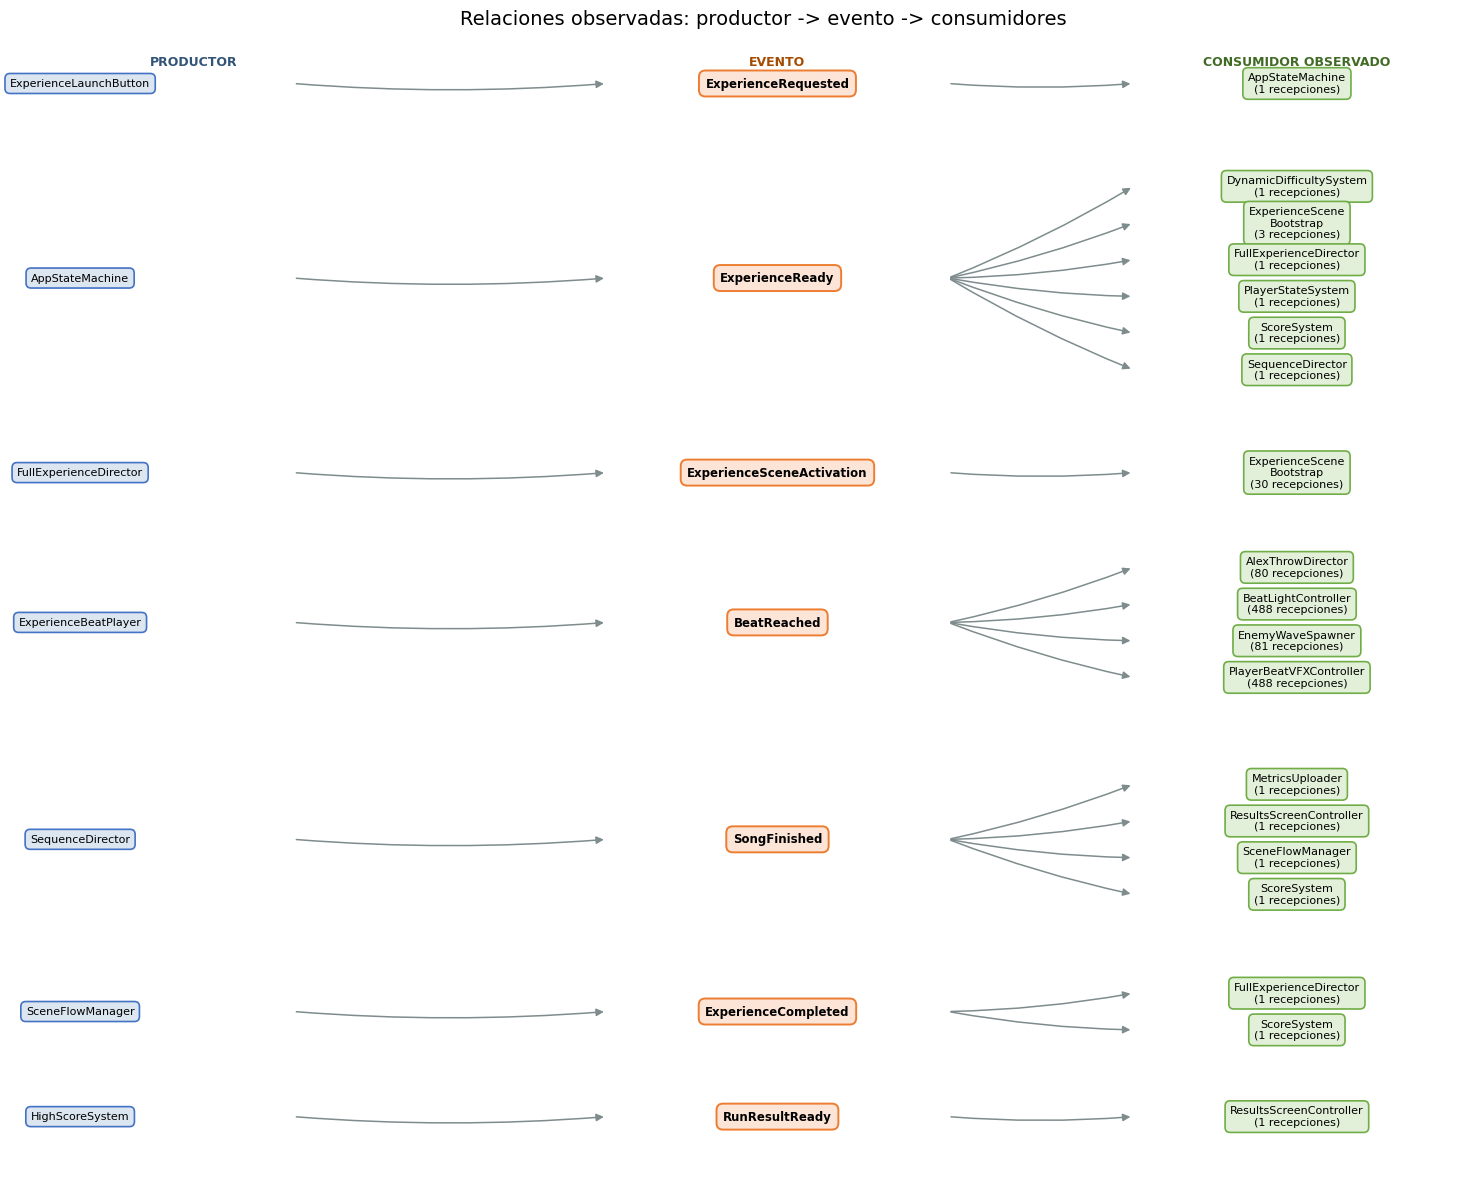

In [68]:
if len(event_relationships):
    preferred_order=['ExperienceRequested','ExperienceReady','ExperienceSceneActivation','BeatReached','SongFinished','ExperienceCompleted','RunResultReady']
    event_groups={name:g.copy() for name,g in event_relationships.groupby('Evento',sort=False)}
    ordered_events=[e for e in preferred_order if e in event_groups]+[e for e in event_groups if e not in preferred_order]
    layout=[]
    cursor=0.0

    for event_name in ordered_events:
        g=event_groups[event_name]
        producers=sorted(g['Productor'].dropna().astype(str).unique())
        consumers=sorted(g['Consumidor observado'].dropna().astype(str).unique())
        row_count=max(len(producers),len(consumers),1)
        center=cursor+(row_count-1)/2
        spread=lambda count:[center+(i-(count-1)/2)*0.82 for i in range(count)]
        producer_y=spread(len(producers)); consumer_y=spread(len(consumers))
        layout.append((event_name,g,producers,consumers,producer_y,consumer_y,center))
        cursor+=row_count+0.85
    fig,ax=plt.subplots(figsize=(15,max(7,cursor*0.48)))
    ax.set_xlim(0,1); ax.set_ylim(cursor-0.5,-0.7); ax.axis('off')
    producer_color='#DCE6F1'; event_color='#FCE4D6'; consumer_color='#E2F0D9'

    for event_name,g,producers,consumers,producer_y,consumer_y,center in layout:
        for producer,y in zip(producers,producer_y):
            producer_label='ExperienceScene\nBootstrap' if producer=='ExperienceSceneBootstrap' else '\n'.join(textwrap.wrap(producer,22,break_long_words=False,break_on_hyphens=False))
            ax.text(0.02,y,producer_label,ha='center',va='center',fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.45',fc=producer_color,ec='#4472C4',lw=1.2))
            ax.add_patch(FancyArrowPatch((0.17,y),(0.39,center),arrowstyle='-|>',mutation_scale=11,
                                         color='#7F8C8D',lw=1.1,connectionstyle='arc3,rad=0.04'))
        ax.text(0.51,center,'\n'.join(textwrap.wrap(str(event_name),25)),ha='center',va='center',fontsize=8.5,fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.55',fc=event_color,ec='#ED7D31',lw=1.4))
        
        for consumer,y in zip(consumers,consumer_y):
            receives=int(g.loc[g['Consumidor observado'].astype(str).eq(consumer),'recepciones_observadas'].sum())
            consumer_label='ExperienceScene\nBootstrap' if consumer=='ExperienceSceneBootstrap' else '\n'.join(textwrap.wrap(consumer,23,break_long_words=False,break_on_hyphens=False))
            label=consumer_label+f'\n({receives:,} recepciones)'
            ax.add_patch(FancyArrowPatch((0.63,center),(0.76,y),arrowstyle='-|>',mutation_scale=11,
                                         color='#7F8C8D',lw=1.1,connectionstyle='arc3,rad=0.04'))
            ax.text(0.875,y,label,ha='center',va='center',fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.45',fc=consumer_color,ec='#70AD47',lw=1.2))
    ax.text(0.10,-0.48,'PRODUCTOR',ha='center',va='center',fontsize=9,fontweight='bold',color='#315477')
    ax.text(0.51,-0.48,'EVENTO',ha='center',va='center',fontsize=9,fontweight='bold',color='#A64B00')
    ax.text(0.875,-0.48,'CONSUMIDOR OBSERVADO',ha='center',va='center',fontsize=9,fontweight='bold',color='#416B25')
    ax.set_title('Relaciones observadas: productor -> evento -> consumidores',fontsize=14,pad=20)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/'relaciones_productor_evento_consumidores.png',dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
else:
    display(Markdown('No hay relaciones productor-consumidor correlacionables en esta ejecuci?n; no se genera el diagrama.'))

La figura se puede observar el componente que publicó, evento distribuido y componentes que lo recibieron. Cada conexión corresponde a una relación encontrada en la captura; el número de paréntesis indica cuantas recepciones registro ese consumidor. Y los eventos se agrupan para mostrar el patrón de comunicación. 

Por ejemplo, la figura permite ver que ExperienceBeatPlayer publicó BeatReached y que los registros muestran varios consumidores con cantidades distintas de recepciones. 



Estas diferencias pueden depender de qué componentes estuvieron activos.

## 5. Pregunta: 3. ¿La coordinación de escenas y beats usó la referencia musical prevista?

Una **frontera musical prevista** es el valor de tiempo musical configurado para que comience un segmento; por ejemplo, 31.16 s para Joaquin en `SEQ_Punko_Final`. La tabla compara ese valor con el `musical_time_s` registrado cuando se activó la escena. La diferencia se calcula como **tiempo musical observado menos frontera prevista**: un valor positivo indica que el registro de activación ocurrió después de esa frontera; uno negativo, antes. Esta comparación solo usa las fronteras documentadas cuando el log identifica `SEQ_Punko_Final`.

,Segmento,Frontera musical prevista (s),Tiempo musical observado (s),Diferencia entre la frontera musical configurada y el tiempo registrado de activación (ms),record_seq,Línea
0,Alex,0.00,0.0178,17.769,217,2276
1,Joaquin,31.16,31.1606,0.552,3322,38673
2,Shipi,62.33,62.3423,12.261,4606,52200
3,JuanAndres,93.50,93.5031,3.056,5797,64302
4,Danniel,124.66,124.6696,9.642,7180,79648
5,Jeremy,155.83,155.8339,3.940,8391,92581


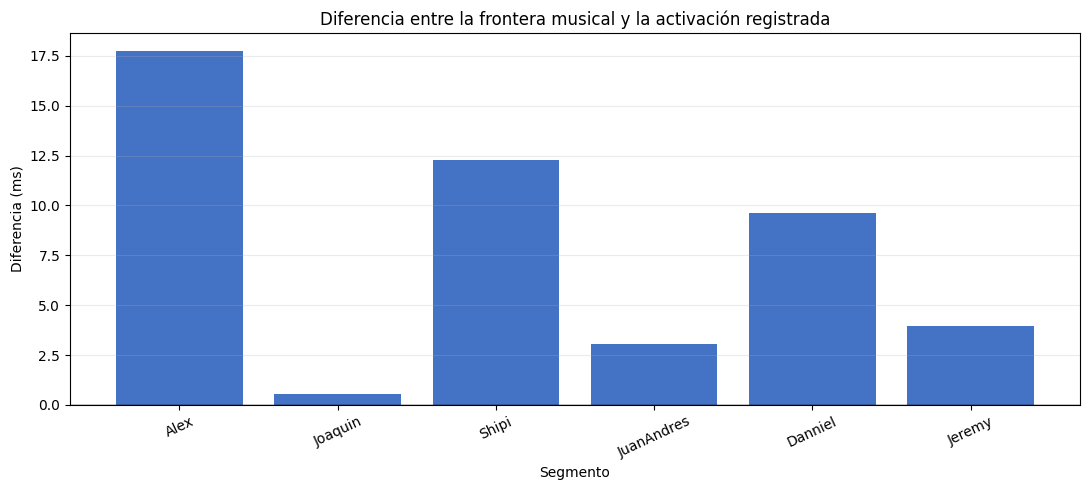

In [69]:
CONFIGURED_BOUNDARIES={'Alex':0.00,'Joaquin':31.16,'Shipi':62.33,'JuanAndres':93.50,'Danniel':124.66,'Jeremy':155.83}  # Contexto documentado; aplicar solo a SEQ_Punko_Final

config_rows=run_df[run_df.action.eq('sequence_configuration')]
sequence_value=config_rows['sequence'].dropna().iloc[0] if len(config_rows) and config_rows['sequence'].notna().any() else None
sequence_name=clean_scene(sequence_value)
segments=run_df[run_df.action.eq('segment_active')].copy(); segments['segment_name']=segments.scene.map(clean_scene)
segments['musical_time_s']=pd.to_numeric(segments.musical_time_s,errors='coerce')
use_config=sequence_name=='SEQ_Punko_Final'
names=list(CONFIGURED_BOUNDARIES) if use_config else segments.sort_values('segment_index').segment_name.dropna().drop_duplicates().tolist()

activation_rows=[]
for name in names:
    hits=segments[segments.segment_name.eq(name)].sort_values('record_seq')
    observed=float(hits.musical_time_s.iloc[0]) if len(hits) and pd.notna(hits.musical_time_s.iloc[0]) else pd.NA
    configured=CONFIGURED_BOUNDARIES.get(name) if use_config else pd.NA
    delta_ms=(float(observed)-float(configured))*1000 if pd.notna(observed) and pd.notna(configured) else pd.NA
    activation_rows.append({'Segmento':name,'Frontera musical prevista (s)':configured,'Tiempo musical observado (s)':observed,
      'Diferencia entre la frontera musical configurada y el tiempo registrado de activación (ms)':delta_ms,
      'record_seq':hits.record_seq.iloc[0] if len(hits) else pd.NA,'Línea':hits.line_no.iloc[0] if len(hits) else pd.NA})
activation_table=pd.DataFrame(activation_rows); display(activation_table.round(4))
valid_activation=bool(use_config and len(activation_table)==6 and activation_table['Tiempo musical observado (s)'].notna().all())

if valid_activation:
    vals=activation_table['Diferencia entre la frontera musical configurada y el tiempo registrado de activación (ms)'].astype(float)
    fig,ax=plt.subplots(figsize=(11,5)); ax.bar(activation_table.Segmento,vals,color='#4472C4'); ax.axhline(0,color='black',linewidth=1)
    ax.set_title('Diferencia entre la frontera musical y la activación registrada'); ax.set_xlabel('Segmento'); ax.set_ylabel('Diferencia (ms)')
    ax.tick_params(axis='x',rotation=25); ax.grid(axis='y',alpha=.25); fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'activacion_segmentos_eda.png',dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
else: display(Markdown('No se generó la gráfica: requiere la configuración SEQ_Punko_Final y tiempo musical válido en las seis activaciones.'))

En la figura, los seis segmentos presentan diferencias positivas: 
Alex, 17.77 ms; Joaquín, 0.55 ms; Shipi, 12.26 ms; Juan Andrés, 3.06 ms; Danniel, 9.64 ms; y Jeremy, 3.94 ms. La diferencia máxima corresponde a Alex y la mínima a Joaquín. 


En la figura se puede ver la diferencia, que esta se calcula como tiempo musical observado menos la frontera prevista, que es el valor de riempo musical configurado para que comience un segmento. Un valor positivo significa que la activación se registro después de la frontera y uno negativo, antes. Es una comparación entre marcas del reloj musical, no representa una latencia audiovisual

### BeatReached como ejemplo de comunicación desacoplada

`ExperienceBeatPlayer` publica `BeatReached` a partir del reloj musical y el mapa de beats. Los consumidores registrados pueden responder o aplicar sus propias reglas. La tabla cuenta publicaciones y recepciones; mantiene aparte omisiones del productor por tolerancia. No suma `handler_returned` ni retornos de distribución como beats.

,Indicador,Cantidad
0,Publicaciones de BeatReached,488
1,Omisiones por exceeded_max_lateness,1
2,Consumidores observados,4


,Consumidor,Recepciones de BeatReached
1,BeatLightController,488
3,PlayerBeatVFXController,488
2,EnemyWaveSpawner,81
0,AlexThrowDirector,80


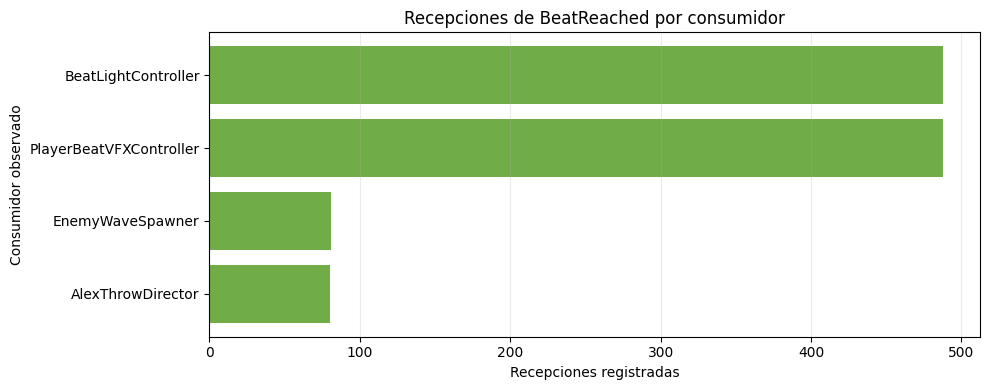

In [70]:
beat_pubs=run_df[run_df.event.eq('BeatReached') & run_df.action.eq('publish')].copy()
beat_recs=run_df[run_df.event.eq('BeatReached') & run_df.action.eq('receive')].copy()
beat_publish_count=int(beat_pubs.loc[beat_pubs.event_id.map(valid_token),'event_id'].nunique())
beat_omissions=run_df[run_df.category.eq('BEAT') & run_df.action.eq('beat_omitted') & run_df.reason.eq('exceeded_max_lateness')]
consumer_counts=beat_recs.groupby('receiver').size().rename('Recepciones de BeatReached').reset_index().rename(columns={'receiver':'Consumidor'}).sort_values('Recepciones de BeatReached',ascending=False)
display(pd.DataFrame([{'Indicador':'Publicaciones de BeatReached','Cantidad':beat_publish_count},{'Indicador':'Omisiones por exceeded_max_lateness','Cantidad':len(beat_omissions)},{'Indicador':'Consumidores observados','Cantidad':int(beat_recs.receiver.nunique())}]))
display(consumer_counts)
if len(consumer_counts):
    plot_counts=consumer_counts.sort_values('Recepciones de BeatReached')
    fig,ax=plt.subplots(figsize=(10,max(4,.55*len(plot_counts)))); ax.barh(plot_counts.Consumidor,plot_counts['Recepciones de BeatReached'],color='#70AD47')
    ax.set_title('Recepciones de BeatReached por consumidor'); ax.set_xlabel('Recepciones registradas'); ax.set_ylabel('Consumidor observado'); ax.grid(axis='x',alpha=.25)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/'consumidores_beatreached.png',dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
    
else: 
    display(Markdown('No hay recepciones de BeatReached en esta ejecución; no se genera la gráfica.'))

La figura de muestra 488 recepciones de \emph{BeatLightController}, 488 de \emph{PlayerBeatVFXController}, 81 de \emph{EnemyWaveSpawner} y 80 de \emph{AlexThrowDirector}. 
En los registros están contados 488 publicaciones y una omisión por parte de \emph{Exceeded max lateness}


Lo que nos indica esta figura es que un mismo evento fue distribuido a distintos consumidores y que las cantidades variaron según los componentes presentos y activos, tomando en cuenta sus reglas. 

### Operaciones de carga y preparación

La tabla resume las operaciones por tipo. La gráfica compara la **mediana de duración registrada** entre operaciones con inicio y desenlace emparejados; `n` indica cuántas operaciones emparejadas entran en cada barra. Sirve para visualizar el peso relativo de la carga y la preparación en esta captura, no para calificar el rendimiento general. Las operaciones de runtime se conservan en la tabla, pero no se incluyen en esta figura para mantener el foco en la carga y preparación.

,Operación,Cantidad,Duración mediana (s),Duración máxima (s),Emparejadas
0,Carga de escena,11,0.125,3.718,11
1,Descarga de escena,14,0.019,0.038,14
2,Preparación de secuencia,1,5.867,5.867,1
3,Preparación de escena,6,0.094,0.416,6
4,Preloader,13,0.014,0.237,13
5,Inicio de runtime,37,0.001,0.004,37
6,Fin de runtime,37,0.000,0.002,37


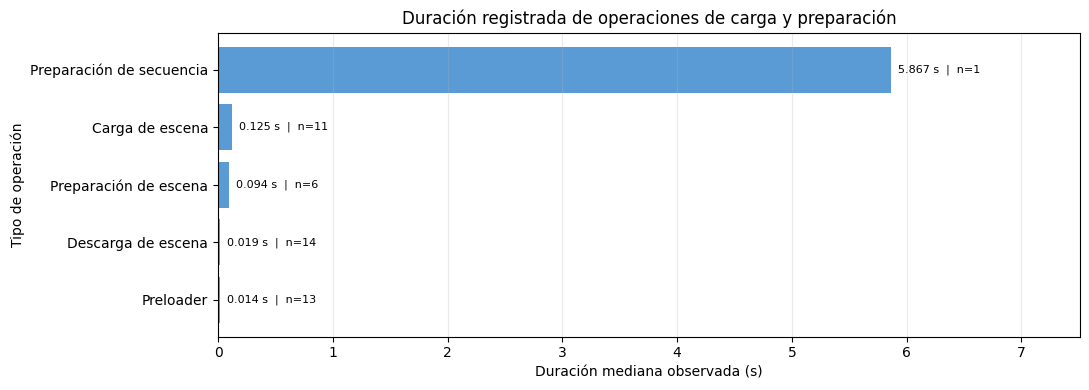

,Escena,Índice,Preparación observada,record_seq,Línea
85,Alex,0,Sí,86,840
98,Joaquin,1,Sí,99,931
115,Danniel,4,Sí,116,1063


In [71]:
opdf=df[df.operation_id.map(valid_token)].copy() if 'operation_id' in df else df.iloc[0:0].copy()
operations=[]
for (run,opid),g in opdf.groupby(['run_key','operation_id'],dropna=False,sort=False):
    for comp, h in g.groupby('component',dropna=False,sort=False):
        h=h.sort_values('line_no'); starts=h[h.phase.astype('string').str.lower().eq('start')] if 'phase' in h else h.iloc[0:0]
        ends=h[h.phase.astype('string').str.lower().isin(['finish','end','complete','completed','cancel','cancelled','error'])] if 'phase' in h else h.iloc[0:0]
        start=starts.iloc[0] if len(starts) else h.iloc[0]
        end=ends.iloc[-1] if len(ends) else None
        dur=(float(end.mono_s)-float(start.mono_s)) if end is not None and pd.notna(end.mono_s) and pd.notna(start.mono_s) else pd.NA
        operations.append({'operation_id':opid,'run_id':run,'component':comp,'scene':start.get('scene'),'source_event_id':start.get('event_id'),
          'start_action':start.get('action'),'start_phase':start.get('phase'),'start_line':start.line_no,'start_seq':start.get('record_seq'),'start_mono_s':start.get('mono_s'),
          'outcome_action':end.get('action') if end is not None else pd.NA,'outcome_phase':end.get('phase') if end is not None else pd.NA,
          'outcome_line':end.line_no if end is not None else pd.NA,'outcome_mono_s':end.get('mono_s') if end is not None else pd.NA,
          'duration_s':dur,'match_status':'emparejada' if end is not None else 'incompleta en la captura',
          'evidence_lines':';'.join(map(str,h.line_no.tolist()))})
operations_df=pd.DataFrame(operations)
ops_selected=operations_df[operations_df.run_id.astype('string').eq(str(SELECTED_RUN_ID))].copy() if SELECTED_RUN_ID is not None else operations_df.copy()
operation_labels={'scene_load_additive':'Carga de escena','full_sequence_prepare':'Preparación de secuencia','scene_prepare':'Preparación de escena','preloader':'Preloader','runtime_begin':'Inicio de runtime','runtime_end':'Fin de runtime','scene_unload':'Descarga de escena'}
ops_selected=ops_selected[ops_selected.start_action.isin(operation_labels)].copy(); ops_selected['Tipo']=ops_selected.start_action.map(operation_labels)
operation_rows=[]
for label,g in ops_selected.groupby('Tipo',sort=False):
    paired=g[g.match_status.eq('emparejada') & g.duration_s.notna()]
    operation_rows.append({'Operación':label,'Cantidad':len(g),'Duración mediana (s)':paired.duration_s.median() if len(paired) else pd.NA,'Duración máxima (s)':paired.duration_s.max() if len(paired) else pd.NA,'Emparejadas':len(paired)})
operation_summary=pd.DataFrame(operation_rows); display(operation_summary.round(3))
plot_operation_types=['Carga de escena','Preparación de secuencia','Preparación de escena','Preloader','Descarga de escena']
plot_ops=operation_summary[operation_summary['Operación'].isin(plot_operation_types)].dropna(subset=['Duración mediana (s)']).sort_values('Duración mediana (s)')
operation_plot_path=OUTPUT_DIR/'operaciones_carga_preparacion.png'
if len(plot_ops):
    fig,ax=plt.subplots(figsize=(11,max(4,.58*len(plot_ops))))
    bars=ax.barh(plot_ops['Operación'],plot_ops['Duración mediana (s)'],color='#5B9BD5')
    ax.set_title('Duración registrada de operaciones de carga y preparación')
    ax.set_xlabel('Duración mediana observada (s)'); ax.set_ylabel('Tipo de operación'); ax.grid(axis='x',alpha=.25)
    ax.margins(x=.28)
    for bar,(_,row) in zip(bars,plot_ops.iterrows()):
        ax.text(bar.get_width(),bar.get_y()+bar.get_height()/2,f"  {row['Duración mediana (s)']:.3f} s  |  n={int(row['Emparejadas'])}",va='center',fontsize=8)
    fig.tight_layout(); fig.savefig(operation_plot_path,dpi=300,bbox_inches='tight'); plt.show(); plt.close(fig)
else:
    if operation_plot_path.exists(): operation_plot_path.unlink()
    display(Markdown('No se generó la gráfica porque no hay duraciones emparejadas para las operaciones de carga y preparación.'))
initial_preloads=run_df[run_df.action.eq('startup_segment_preload_selected')].copy()
initial_preloads['Escena']=initial_preloads.scene.map(clean_scene)
initial_preloads['Preparación observada']=initial_preloads.segment_index.map(lambda x:'Sí' if ((run_df.action.eq('segment_scene_prepared')) & run_df.segment_index.eq(x)).any() else 'Sin registro')
initial_preloads=initial_preloads[['Escena','segment_index','Preparación observada','record_seq','line_no']].rename(columns={'segment_index':'Índice','line_no':'Línea'})
display(initial_preloads)


La pregarga inicial identifica escenas preparadas antes de su activación.

Acerca de la figura, la mediana registrada para la preparación de la secuencia fue de 
5.867 s (n=1); para la carga de escena, 0.125 (n=11); para la preparación de escena, 0.094 s (n=6); para la descarga de escena, 0.019 s (n=14); y para el preloader, 0.014 s (n=13).
%%

### Resultados principales de la trazabilidad EDA
La siguiente tabla resume los hallazgos de las tres preguntas. Cada resultado se deriva de los registros de la ejecución seleccionada.

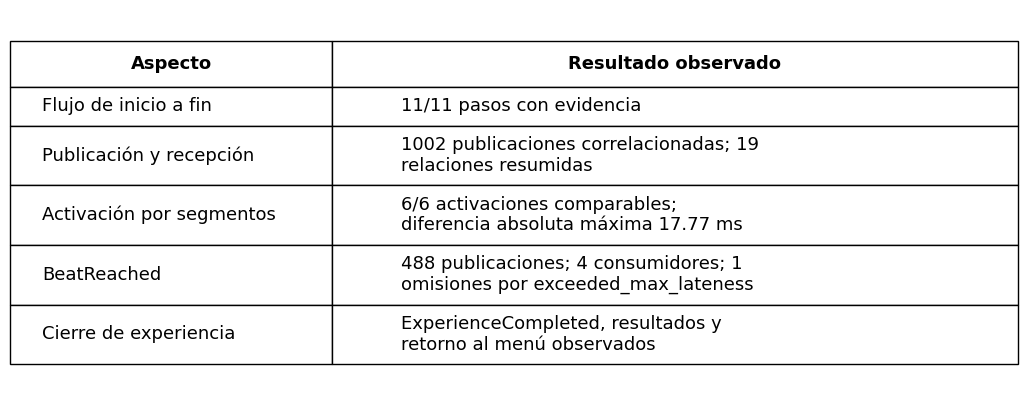

Imagen guardada en: C:\Users\angel\OneDrive\Documentos\.universidad\.2026\s2\tg\PG-analisis-resultados\Eventos\resultados_trazabilidad_EDA\results_main.png


In [82]:
results_export = results_main.copy()

results_export["Resultado observado"] = (
    results_export["Resultado observado"]
    .astype(str)
    .apply(
        lambda texto: "\n".join(
            textwrap.wrap(
                texto,
                width=38,
                break_long_words=False,
                break_on_hyphens=False
            )
        )
    )
)


results_export["Aspecto"] = (
    results_export["Aspecto"]
    .astype(str)
    .apply(
        lambda texto: "\n".join(
            textwrap.wrap(
                texto,
                width=25,
                break_long_words=False,
                break_on_hyphens=False
            )
        )
    )
)


fig, ax = plt.subplots(figsize=(13, 5))
ax.axis("off")

tabla = ax.table(
    cellText=results_export.values,
    colLabels=results_export.columns,
    cellLoc="left",
    colLoc="center",
    loc="center",
    colWidths=[0.32, 0.68]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(13)


for fila in range(1, len(results_export) + 1):
    max_lineas = max(
        results_export.iloc[fila - 1].astype(str)
        .apply(lambda x: x.count("\n") + 1)
    )

    altura = 0.10 + (max_lineas - 1) * 0.055

    for columna in range(len(results_export.columns)):
        tabla[(fila, columna)].set_height(altura)

for columna in range(len(results_export.columns)):
    tabla[(0, columna)].set_text_props(weight="bold")
    tabla[(0, columna)].set_height(0.12)

archivo = Path("resultados_trazabilidad_EDA/results_main.png")
archivo.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    archivo,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Imagen guardada en:", archivo.resolve())
# display(Image(filename=str(archivo)))

La tabla de resultados principales resume que 11 de 11 pasos de flujo con evidencia se realizaron; hay 1002 publicaciones correlacionadas en 19 relaciones resumidas; 
6 de 6 activaciones de segmentos comparables, con una diferencia absoluta máxima de 17.77 ms;
488 publicaciones de \emph{BeatReached}, cuatro consumidores y una omisión; 
y registros de \emph{ExperienceCompleted} para el cierre de la experiencia con recepción de resultados y retorno al menú.


Se reconstruyó el recorrido de esta ejecución por medio de identificadores de eventos y operaciones: solicitud, preparación, ExperienceReady, cambios de segmento, publicaciones rítmicas y cierre. Una publicación puede llegar a diferentes consumidores sin que el productor ejecute directamente sus respuestas. 

## Limitaciones del análisis

- Se analizó una ejecución; los resultados no describen la variabilidad entre corridas.
- Los logs muestran los puntos instrumentados, no todas las operaciones internas posibles.
- La ausencia de un registro no demuestra automáticamente que una acción no ocurriera; Logcat no ofrece aquí un contador fiable de pérdidas por saturación.
- Las diferencias musicales no representan latencia audiovisual percibida.
- El análisis evalúa trazabilidad funcional, no rendimiento general.

## Anexo técnico: integridad y diagnóstico de los registros

Esta sección conserva las tablas completas de eventos, operaciones y suscripciones se muestran aquí; los CSV preservan todas las filas, identificadores y líneas originales. Las trazas de pila se conservan en `evidencia_complementaria.csv` y no se cuentan como eventos.

In [73]:
schema=pd.DataFrame({'Columna':df.columns,'Tipo':[str(df[c].dtype) for c in df.columns],'Valores presentes':[int(df[c].notna().sum()) for c in df.columns]})
category_counts=df.category.value_counts(dropna=False).rename_axis('Categoría').reset_index(name='Registros')
exact_duplicates=df[df.duplicated('raw_text',keep=False)].sort_values('line_no')
seq_rows=df[df.record_seq.notna()].sort_values('line_no').copy()
conflict_seq_values=seq_rows.groupby('record_seq').raw_text.nunique(); conflict_seq_values=conflict_seq_values[conflict_seq_values.gt(1)].index
seq_conflicts=seq_rows[seq_rows.record_seq.isin(conflict_seq_values)].sort_values(['record_seq','line_no'])
seq_gaps=[]; seq_values=seq_rows.record_seq.astype('int64').tolist()

for a,b in zip(seq_values,seq_values[1:]):
    if b-a>1: seq_gaps.append({'record_seq previo':a,'record_seq siguiente':b,'secuencias ausentes':b-a-1})
mono_rows=df[df.mono_s.notna()].sort_values('line_no'); mono_resets=[]

for i in range(1,len(mono_rows)):
    before=mono_rows.iloc[i-1]; after=mono_rows.iloc[i]
    if after.mono_s<before.mono_s: mono_resets.append({'línea anterior':int(before.line_no),'mono_s anterior':float(before.mono_s),'línea posterior':int(after.line_no),'mono_s posterior':float(after.mono_s)})
quality_main=pd.DataFrame([
 {'Control':'Líneas originales','Resultado':len(raw_lines)},{'Control':'Registros estructurados','Resultado':len(df)},
 {'Control':'Líneas de evidencia auxiliar','Resultado':len(complement_df)},{'Control':'Errores de extracción','Resultado':len(issues_df)},
 {'Control':'Errores de conversión','Resultado':len(conversion_issues_df)},{'Control':'Filas de duplicados idénticos','Resultado':len(exact_duplicates)},
 {'Control':'Filas con record_seq conflictivo','Resultado':len(seq_conflicts)},{'Control':'Saltos de record_seq','Resultado':len(seq_gaps)},{'Control':'Retrocesos de mono_s','Resultado':len(mono_resets)}])

display(quality_main); display(category_counts)
display(Markdown('Un salto de record_seq describe una discontinuidad del registro; no demuestra por sí solo pérdida de un evento funcional. Los originales no se deduplican ni modifican.'))
display(Markdown('Esquema completo para auditoría técnica:')); display(schema)
actions_full=df.action.value_counts(dropna=False).rename_axis('action').reset_index(name='registros')
display(actions_full)

,Control,Resultado
0,Líneas originales,102061
1,Registros estructurados,9426
2,Líneas de evidencia auxiliar,92635
3,Errores de extracción,0
4,Errores de conversión,0
5,Filas de duplicados idénticos,0
6,Filas con record_seq conflictivo,0
7,Saltos de record_seq,0
8,Retrocesos de mono_s,0


,Categoría,Registros
0,EDA,7388
1,BEAT,1144
2,OP,287
3,SCORE,225
4,METRICS,221
5,FLOW,126
6,TRANSITION,20
7,CONFIG,7
8,AUDIO,3
9,HEADER,2


Un salto de record_seq describe una discontinuidad del registro; no demuestra por sí solo pérdida de un evento funcional. Los originales no se deduplican ni modifican.

Esquema completo para auditoría técnica:

,Columna,Tipo,Valores presentes
0,file,object,9426
1,line_no,int64,9426
2,category,object,9426
3,raw_text,object,9426
4,parse_issue,object,0
...,...,...,...
137,cancelled,boolean,1
138,credits_in_progress,boolean,1
139,main_menu_loaded,boolean,1
140,capture_id,object,9426


,action,registros
0,receive,2638
1,handler_returned,2638
2,handler_dispatch_returned,1003
3,publish,1003
4,consumer_discarded_beat,611
...,...,...
76,experience_completion_requested,1
77,run_result_published,1
78,results_received,1
79,closing_cancel_requested,1


In [74]:
display(event_catalog)
display(event_chains)
display(Markdown(f"Publicaciones sin recepción correlacionada: {len(unmatched_pubs)}. Recepciones sin publicación correlacionada: {len(unmatched_recs)}. La ausencia de evidencia no se interpreta automáticamente como fallo."))
display(unmatched_pubs); display(unmatched_recs)

,channel,channel_ids,publisher_components,receiver_components,publisher_instances_scenes,receiver_instances_scenes,publications,receives,subscriptions
0,BeatEffects,99316,ExperienceBeatPlayer,AlexThrowDirector; BeatLightController; EnemyW...,ExperienceBeatPlayer#99316@ExperienceCore,AlexThrowDirector#99518@Alex; BeatLightControl...,490,1141,11
1,DifficultyChanged,46736,DynamicDifficultySystem,AlexThrowDirector; DannielDifficultyController...,DynamicDifficultySystem#99308@ExperienceCore,AlexThrowDirector#99518@Alex; DannielDifficult...,10,21,5
2,ExperienceCompleted,47016,SceneFlowManager,FullExperienceDirector; ScoreSystem,SceneFlowManager#61700@Bootstrap,FullExperienceDirector#61770@Bootstrap; ScoreS...,1,2,4
3,ExperienceReady,46728,AppStateMachine,DynamicDifficultySystem; ExperienceSceneBootst...,AppStateMachine#61758@Bootstrap,DynamicDifficultySystem#99308@ExperienceCore; ...,1,8,22
4,ExperienceRequested,32974,ExperienceLaunchButton,AppStateMachine,ExperienceLaunchButton#98980@MainMenu,AppStateMachine#61758@Bootstrap,1,1,2
5,ExperienceSceneActivation,47136,FullExperienceDirector,ExperienceSceneBootstrap,FullExperienceDirector#61770@Bootstrap,ExperienceSceneBootstrap#100050@Shipi; Experie...,12,30,12
6,ExperienceTransitionStarted,47756,AppStateMachine,AudioManager,AppStateMachine#61758@Bootstrap,AudioManager#61748@Bootstrap,1,1,2
7,FinalScoreSubmitted,48256,ScoreSystem,HighScoreSystem,ScoreSystem#99262@ExperienceCore,HighScoreSystem#61676@Bootstrap,1,1,2
8,GameplayPauseChanged,47724,PauseMenuController; ResultsScreenController; ...,JeremySwordAttachment; MetricsSystem; PlayerSt...,PauseMenuController#99414@ExperienceCore; Resu...,JeremySwordAttachment#100334@Jeremy; JeremySwo...,4,14,4
9,InteractionRegistered,47084,AlexThrowDirector; DannielInteractionControlle...,DynamicDifficultySystem; JuanAndresDogFeedback...,AlexThrowDirector#99518@Alex; DannielInteracti...,DynamicDifficultySystem#99308@ExperienceCore; ...,221,917,8


,capture_id,run_id,event_id,channel,channel_id,publisher,publisher_instance,publisher_scene,receiver,receiver_instance,receiver_scene,publish_seq,receive_seq,publish_line,receive_line,publish_mono_s,receive_mono_s,instrumented_delta_ms,correlation,event
0,capture-001,<NA>,evt-1,MainMenuEntered,48174,AppStateMachine,61758,Bootstrap,AudioManager,61748,Bootstrap,18,19,132,142,2.390425,2.390951,0.526,event_id + capture/run + compatible channel,MainMenuEntered
1,capture-001,<NA>,evt-1,MainMenuEntered,48174,AppStateMachine,61758,Bootstrap,MainMenuEffectsController,99030,MainMenu,18,22,132,185,2.390425,2.656807,266.382,event_id + capture/run + compatible channel,MainMenuEntered
2,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-2,ScoreRunStarted,47690,ExperienceLaunchButton,98980,MainMenu,HighScoreSystem,61676,Bootstrap,28,29,299,309,19.677458,19.677660,0.202,event_id + capture/run + compatible channel,ScoreRunStarted
3,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-3,ExperienceRequested,32974,ExperienceLaunchButton,98980,MainMenu,AppStateMachine,61758,Bootstrap,33,34,351,361,19.678863,19.679059,0.196,event_id + capture/run + compatible channel,ExperienceRequested
4,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-4,ExperienceTransitionStarted,47756,AppStateMachine,61758,Bootstrap,AudioManager,61748,Bootstrap,38,39,421,439,19.681130,19.681356,0.226,event_id + capture/run + compatible channel,ExperienceTransitionStarted
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2633,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-1001,GameplayPauseChanged,47724,PauseMenuController,99414,ExperienceCore,PlayerStateSystem,99296,ExperienceCore,9361,9366,101490,101540,221.031523,221.032101,0.578,event_id + capture/run + compatible channel,GameplayPauseChanged
2634,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-1002,BeatEffects,99316,ExperienceBeatPlayer,99316,ExperienceCore,PlayerBeatVFXController,99304,ExperienceCore,9371,9372,101582,101590,221.032809,221.032906,0.097,event_id + capture/run + compatible channel,PlaybackReset
2635,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-1002,BeatEffects,99316,ExperienceBeatPlayer,99316,ExperienceCore,BeatLightController,99314,ExperienceCore,9371,9375,101582,101616,221.032809,221.033132,0.323,event_id + capture/run + compatible channel,PlaybackReset
2636,capture-001,c5821b1ffe684c4dbaf68681ecc7f269,evt-1003,MainMenuEntered,48174,AppStateMachine,61758,Bootstrap,AudioManager,61748,Bootstrap,9408,9409,101847,101857,221.115336,221.115461,0.125,event_id + capture/run + compatible channel,MainMenuEntered


Publicaciones sin recepción correlacionada: 0. Recepciones sin publicación correlacionada: 0. La ausencia de evidencia no se interpreta automáticamente como fallo.

,file,line_no,category,raw_text,parse_issue,unparsed_residue,record_seq,mono_s,reason,app_version,...,upload_finished,final_score,high_score,is_new_high_score,new_high_score,cancelled,credits_in_progress,main_menu_loaded,capture_id,run_key


,file,line_no,category,raw_text,parse_issue,unparsed_residue,record_seq,mono_s,reason,app_version,...,upload_finished,final_score,high_score,is_new_high_score,new_high_score,cancelled,credits_in_progress,main_menu_loaded,capture_id,run_key


In [75]:
display(operations_df)
display(subs[['line_no','record_seq','run_key','event_id','action','component','instance_id','scene','channel','channel_id']].sort_values('line_no'))
scene_timeline=run_df[run_df.action.isin(['scene_prepare','segment_scene_prepared','transition_phase_started','transition_phase_finished','segment_active','segment_deactivation_requested','scene_unload'])].copy()
display(scene_timeline)
beat_summary=run_df[run_df.category.eq('BEAT')].groupby(['action','component','consumer','reason'],dropna=False).size().rename('registros').reset_index()
display(beat_summary); display(conversion_issues_df); display(issues_df)

,operation_id,run_id,component,scene,source_event_id,start_action,start_phase,start_line,start_seq,start_mono_s,outcome_action,outcome_phase,outcome_line,outcome_mono_s,duration_s,match_status,evidence_lines
0,op-1,<NA>,SceneFlowManager,Bootstrap,none,scene_load_additive,start,75,13,0.369074,scene_load_additive,finish,102,2.297395,1.928321,emparejada,75;102
1,op-2,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,evt-3,transition_to_experience,start,532,43,19.684043,transition_to_experience,finish,1310,25.696246,6.012203,emparejada,532;1310
2,op-3,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,evt-3,scene_load_additive,start,562,45,19.684548,scene_load_additive,finish,597,19.716110,0.031562,emparejada,562;597
3,op-4,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_unload,start,611,50,19.738154,scene_unload,finish,624,19.752400,0.014246,emparejada,611;624
4,op-5,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_load_additive,start,631,53,19.752574,scene_load_additive,finish,814,19.804940,0.052366,emparejada,631;814
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,op-136,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_load_additive,start,101436,9353,220.961651,scene_load_additive,finish,101443,220.990067,0.028416,emparejada,101436;101443
136,op-137,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_unload,start,101457,9356,221.009800,scene_unload,finish,101464,221.010036,0.000236,emparejada,101457;101464
137,op-138,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_unload,start,101471,9358,221.017858,scene_unload,finish,101770,221.036637,0.018779,emparejada,101471;101770
138,op-139,c5821b1ffe684c4dbaf68681ecc7f269,SceneFlowManager,Bootstrap,none,scene_load_additive,start,101777,9400,221.036745,scene_load_additive,finish,101800,221.078253,0.041508,emparejada,101777;101800


,line_no,record_seq,run_key,event_id,action,component,instance_id,scene,channel,channel_id
1,9,2,<NA>,none,subscription_added,FullExperienceDirector,61770,Bootstrap,ExperienceReady,46728
2,15,3,<NA>,none,subscription_added,FullExperienceDirector,61770,Bootstrap,ExperienceCompleted,47016
3,21,4,<NA>,none,subscription_added,FullExperienceDirector,61770,Bootstrap,MainMenuRequested,48432
4,27,5,<NA>,none,subscription_added,HighScoreSystem,61676,Bootstrap,ScoreRunStarted,47690
5,33,6,<NA>,none,subscription_added,HighScoreSystem,61676,Bootstrap,FinalScoreSubmitted,48256
...,...,...,...,...,...,...,...,...,...,...
9421,102032,9422,<NA>,none,subscription_removed,FullExperienceDirector,61770,Bootstrap,MainMenuRequested,48432
9422,102038,9423,<NA>,none,subscription_removed,AudioManager,61748,Bootstrap,MainMenuEntered,48174
9423,102044,9424,<NA>,none,subscription_removed,AudioManager,61748,Bootstrap,ExperienceTransitionStarted,47756
9424,102050,9425,<NA>,none,subscription_removed,HighScoreSystem,61676,Bootstrap,ScoreRunStarted,47690


,file,line_no,category,raw_text,parse_issue,unparsed_residue,record_seq,mono_s,reason,app_version,...,upload_finished,final_score,high_score,is_new_high_score,new_high_score,cancelled,credits_in_progress,main_menu_loaded,capture_id,run_key
49,PUNKO_CONSOLE_LOG.txt,611,OP,[PGDIAG][OP] record_seq=50 mono_s=19.738154 ru...,None,,50,19.738154,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
51,PUNKO_CONSOLE_LOG.txt,624,OP,[PGDIAG][OP] record_seq=52 mono_s=19.752400 ru...,None,,52,19.7524,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
92,PUNKO_CONSOLE_LOG.txt,885,OP,[PGDIAG][OP] record_seq=93 mono_s=20.147090 ru...,None,,93,20.14709,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
95,PUNKO_CONSOLE_LOG.txt,910,OP,[PGDIAG][OP] record_seq=96 mono_s=20.397934 ru...,None,,96,20.397934,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
96,PUNKO_CONSOLE_LOG.txt,919,FLOW,[PGDIAG][FLOW] record_seq=97 mono_s=20.398345 ...,None,,97,20.398345,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9356,PUNKO_CONSOLE_LOG.txt,101464,OP,[PGDIAG][OP] record_seq=9357 mono_s=221.010036...,None,,9357,221.010036,empty_scene_name,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
9357,PUNKO_CONSOLE_LOG.txt,101471,OP,[PGDIAG][OP] record_seq=9358 mono_s=221.017858...,None,,9358,221.017858,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
9398,PUNKO_CONSOLE_LOG.txt,101770,OP,[PGDIAG][OP] record_seq=9399 mono_s=221.036637...,None,,9399,221.036637,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269
9403,PUNKO_CONSOLE_LOG.txt,101814,OP,[PGDIAG][OP] record_seq=9404 mono_s=221.078874...,None,,9404,221.078874,NaN,NaN,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,capture-001,c5821b1ffe684c4dbaf68681ecc7f269


,action,component,consumer,reason,registros
0,beat_omitted,ExperienceBeatPlayer,NaN,exceeded_max_lateness,1
1,clear_particles,PlayerBeatVFXController,PlayerBeatVFXController,NaN,2
2,consumer_discarded_beat,AlexThrowDirector,AlexThrowDirector,beat_interval_filter,17
3,consumer_discarded_beat,BeatLightController,BeatLightController,below_intensity_or_empty_palette,297
4,consumer_discarded_beat,PlayerBeatVFXController,PlayerBeatVFXController,inactive_dependency_paused_low_intensity_dupli...,297
5,emit_particles,PlayerBeatVFXController,PlayerBeatVFXController,NaN,191
6,launch_throw_pair,AlexThrowDirector,AlexThrowDirector,NaN,63
7,light_color_pulse,BeatLightController,BeatLightController,NaN,191
8,queue_throw,AlexThrowDirector,AlexThrowDirector,NaN,63
9,reset_light_pulse,BeatLightController,BeatLightController,NaN,2


,file,line_no,field,value,problem


""


### Exportaciones

El detalle queda en un CSV. Las cinco figuras principales se guardan como PNG; la gráfica de activaciones solo se crea si hay datos válidos para los seis segmentos. Las tablas PNG contienen los resúmenes.

In [76]:
def save_table_png(table,title,filename,max_rows=25):
    if table is None or table.empty: return
    view=table.head(max_rows).astype(str)
    fig,ax=plt.subplots(figsize=(14,max(2.5,.40*len(view)+1)))
    ax.axis('off'); ax.set_title(title,loc='left',fontsize=12,pad=10)
    t=ax.table(cellText=view.values,colLabels=view.columns,loc='center',cellLoc='left')
    t.auto_set_font_size(False); t.set_fontsize(7); t.scale(1,1.2)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/filename,dpi=300,bbox_inches='tight'); plt.close(fig)


old_visuals=['eventos_por_tipo_y_etapa.png','suscripciones_por_canal.png','trazabilidad_evento_seleccionado.png','registros_por_categoria.png','tiempo_monotonico.png','catalogo_eventos.png','contexto_corridas.png','cobertura_flujo.png','operaciones.png']
for name in old_visuals:
    target=OUTPUT_DIR/name
    if target.exists(): target.unlink()
if not valid_activation:
    target=OUTPUT_DIR/'activacion_segmentos_eda.png'
    if target.exists(): target.unlink()
save_table_png(coverage_main,'Cobertura del flujo EDA','tabla_cobertura_flujo_eda.png',15)
save_table_png(event_relationships,'Relaciones observadas entre productores y consumidores','tabla_eventos_eda.png',25)

coverage_detail=pd.concat([hits.assign(etapa=stage) for stage,mask_fn in coverage_specs for hits in [run_df.loc[mask_fn(run_df)]]],ignore_index=True) if coverage_specs else pd.DataFrame()
exports={
 'registros_estructurados.csv':df,'evidencia_complementaria.csv':complement_df,
 'problemas_parseo.csv':issues_df,'problemas_conversion.csv':conversion_issues_df,
 'duplicados_exactos.csv':exact_duplicates,'secuencias_conflictivas.csv':seq_conflicts,
 'discontinuidades_record_seq.csv':pd.DataFrame(seq_gaps),'retrocesos_mono_s.csv':pd.DataFrame(mono_resets),
 'calidad_registros.csv':quality_main,'categorias_registros.csv':category_counts,'acciones_completas.csv':actions_full,
 'contexto_ejecucion.csv':summary,'cobertura_flujo.csv':coverage_main,'cobertura_flujo_detallada.csv':coverage_detail,
 'relaciones_productor_consumidor.csv':event_relationships,'eventos_correlacionados_completos.csv':event_chains,
 'publicaciones_sin_recepcion.csv':unmatched_pubs,'recepciones_sin_publicacion.csv':unmatched_recs,
 'catalogo_eventos.csv':event_catalog,'operaciones_resumen.csv':operation_summary,'operaciones_completas.csv':operations_df,
 'suscripciones_completas.csv':subs,'activacion_segmentos.csv':activation_table,'beat_recepciones_consumidor.csv':consumer_counts,
 'beat_omisiones.csv':beat_omissions,'resultados_principales.csv':results_main,'secuencia_escenas.csv':scene_timeline,
 'resumen_beats_detallado.csv':beat_summary,'resumen_eventos_por_etapa.csv':event_rows if 'event_rows' in globals() else pd.DataFrame()}
for filename,table in exports.items(): table.to_csv(OUTPUT_DIR/filename,index=False,encoding='utf-8-sig')
print(f"Exportacion completa: {len(exports)} CSV; PNG: {', '.join(sorted(p.name for p in OUTPUT_DIR.glob('*.png')))}")



Exportacion completa: 29 CSV; PNG: activacion_segmentos_eda.png, consumidores_beatreached.png, flujo_temporal_eda.png, operaciones_carga_preparacion.png, relaciones_productor_evento_consumidores.png, results_main.png, tabla_cobertura_flujo_eda.png, tabla_eventos_eda.png
